# 🌱 Peak-KAN — Multi-Species Kolmogorov-Arnold Network Classifier
## Supervised Species Classification from Seismic Footstep Features (KAN only — no GCN/GAT)

**Strategy:** Same footstep-peak feature extraction as the GCN/GAT notebooks, but the model
itself is a **pure Kolmogorov-Arnold Network (KAN)** — no graph convolutions, no attention,
no message passing at all. Each edge between layers learns its own spline-based function
instead of a fixed activation + single weight, which is the core idea behind KANs (Liu et al.,
2024) as an alternative to standard MLPs.

**How it works:**
- **Feature extraction:** identical peak-detection logic as before — footstep impact peaks give
  an 8-D feature vector per peak (magnitude, 3-axis components, prominence, energy, std, position).
- **Pooling (new):** since KAN needs one fixed-size vector per sample (not a variable-size graph),
  we pool all peak feature vectors per sample using mean + max + std → a 24-D vector.
- **Scaling:** features are standardized (zero mean / unit variance) since KAN's spline grid
  expects roughly bounded inputs.
- **Model:** a stack of `KANLinear` layers (24 → 32 → 16 → num_classes), each learning its own
  per-edge spline function instead of a plain matrix multiply + activation.
- **Loss:** `CrossEntropyLoss` on the real species label.

**Dataset:** `dset_allspec_150_chunks_clean.nc` — all classes kept, no filtering.


---
## 🔧 STEP 1: Setup & GPU Configuration
**What I'm doing:** Importing PyTorch, checking CUDA/GPU availability, auto-selecting the GPU
with the most free VRAM, and fixing random seeds for reproducibility.


In [1]:
import torch, os, math, numpy as np
print(f'PyTorch version : {torch.__version__}')
print(f'CUDA available  : {torch.cuda.is_available()}')

if torch.cuda.is_available():
    num_gpus = torch.cuda.device_count()
    print(f'GPU count       : {num_gpus}')
    best_gpu_idx = 0
    max_free_mem = 0
    print('\nChecking VRAM availability across all GPUs:')
    for i in range(num_gpus):
        try:
            free_mem, total_mem = torch.cuda.mem_get_info(i)
            free_gb  = free_mem  / (1024**3)
            total_gb = total_mem / (1024**3)
            print(f'  GPU {i}: {torch.cuda.get_device_name(i):22s} | Free: {free_gb:5.1f} GB / {total_gb:5.1f} GB')
            if free_mem > max_free_mem:
                max_free_mem = free_mem
                best_gpu_idx = i
        except Exception as e:
            print(f'  GPU {i}: Could not query memory ({e})')
    device = torch.device(f'cuda:{best_gpu_idx}')
    torch.cuda.set_device(device)
    torch.cuda.empty_cache()
    print(f'\n🚀 Automatically selected GPU {best_gpu_idx} ({torch.cuda.get_device_name(best_gpu_idx)}) with {max_free_mem/(1024**3):.1f} GB free VRAM!')
else:
    device = torch.device('cpu')
    print('Using device    : cpu')

SEED = 42; torch.manual_seed(SEED); np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print('Setup complete ✓')


PyTorch version : 2.8.0+cu128
CUDA available  : True
GPU count       : 8

Checking VRAM availability across all GPUs:
  GPU 0: NVIDIA A100-SXM4-80GB  | Free:  20.7 GB /  79.2 GB
  GPU 1: NVIDIA A100-SXM4-80GB  | Free:  39.1 GB /  79.2 GB
  GPU 2: NVIDIA A100-SXM4-80GB  | Free:  68.4 GB /  79.2 GB
  GPU 3: NVIDIA A100-SXM4-80GB  | Free:  68.5 GB /  79.2 GB
  GPU 4: NVIDIA A100-SXM4-80GB  | Free:  62.8 GB /  79.2 GB
  GPU 5: NVIDIA A100-SXM4-80GB  | Free:  68.0 GB /  79.2 GB
  GPU 6: NVIDIA A100-SXM4-80GB  | Free:  61.9 GB /  79.2 GB
  GPU 7: NVIDIA A100-SXM4-80GB  | Free:  24.1 GB /  79.2 GB

🚀 Automatically selected GPU 3 (NVIDIA A100-SXM4-80GB) with 68.5 GB free VRAM!
Setup complete ✓


---
## 📂 STEP 2: Load Dataset & Inspect Class Distribution
**What I'm doing:** Opening the NetCDF dataset and listing how many recordings exist per class.
No filtering — every species stays in the dataset.

Edit `CLASS_NAMES` below to match your actual species labels.


In [2]:
import netCDF4 as nc

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'
dataset = nc.Dataset(FILE_PATH, mode='r')
print('Variable Shapes:')
for v in dataset.variables.keys():
    print(f'  {v:12s}: {dataset.variables[v].shape}')

all_labels_raw = dataset['class'][:].astype(int)
unique_classes, class_counts = np.unique(all_labels_raw, return_counts=True)
print(f'\nTotal recordings in NetCDF: {len(all_labels_raw)}')
for cls, cnt in zip(unique_classes, class_counts):
    pct = cnt / len(all_labels_raw) * 100
    print(f'  Class {cls:3d}: {cnt:6d} samples  ({pct:.1f}%)')

# ── EDIT THIS to your real species names ────────────────────────────────────
CLASS_NAMES = {int(c): f'Class {int(c)}' for c in unique_classes}
CLASS_NAMES[1] = 'Elephant'   # known from earlier notebooks — fill in the rest, e.g.:
# CLASS_NAMES[2] = 'Rhino'
# CLASS_NAMES[3] = 'Human'
# CLASS_NAMES[0] = 'Background/Noise'

print('\nClass name mapping in use:')
for c in unique_classes:
    print(f'  {int(c)} -> {CLASS_NAMES[int(c)]}')


Variable Shapes:
  chunk       : (70637, 3, 2048)
  class       : (70637,)
  distance    : (70637,)
  seis        : (70637,)
  image       : (70637, 128, 128, 3)

Total recordings in NetCDF: 70637
  Class   0:   2073 samples  (2.9%)
  Class   1:  62493 samples  (88.5%)
  Class   2:    164 samples  (0.2%)
  Class   3:      2 samples  (0.0%)
  Class   4:    271 samples  (0.4%)
  Class   5:    769 samples  (1.1%)
  Class   6:   4321 samples  (6.1%)
  Class   7:     42 samples  (0.1%)
  Class   8:     10 samples  (0.0%)
  Class   9:    488 samples  (0.7%)
  Class  11:      4 samples  (0.0%)

Class name mapping in use:
  0 -> Class 0
  1 -> Elephant
  2 -> Class 2
  3 -> Class 3
  4 -> Class 4
  5 -> Class 5
  6 -> Class 6
  7 -> Class 7
  8 -> Class 8
  9 -> Class 9
  11 -> Class 11


---
## 🎯 STEP 3: Load Raw Signals for ALL Classes
**What I'm doing:** Loading raw signal/image/distance arrays for every sample, and remapping raw
class IDs to a contiguous `0..num_classes-1` range (required by `CrossEntropyLoss`).


In [3]:
print('Loading raw signal data for ALL species...')
all_chunks_raw = dataset['chunk'][:]
all_images_raw = dataset['image'][:]
all_distances  = dataset['distance'][:]
dataset.close()

selected_chunks = all_chunks_raw
selected_images = all_images_raw
selected_dist   = all_distances
raw_labels      = all_labels_raw

sorted_raw_classes = sorted(CLASS_NAMES.keys())
raw_to_idx = {raw: i for i, raw in enumerate(sorted_raw_classes)}
idx_to_name = {i: CLASS_NAMES[raw] for raw, i in raw_to_idx.items()}
num_classes = len(sorted_raw_classes)

print(f'Total samples (all species) : {len(selected_chunks):,}')
print(f'Number of classes           : {num_classes}')
print(f'Signal shape per sample     : {selected_chunks[0].shape}  (3 comp x 2048 time)')
print('\nLabel index -> species name:')
for i in range(num_classes):
    print(f'  {i} -> {idx_to_name[i]}')


Loading raw signal data for ALL species...
Total samples (all species) : 70,637
Number of classes           : 11
Signal shape per sample     : (3, 2048)  (3 comp x 2048 time)

Label index -> species name:
  0 -> Class 0
  1 -> Elephant
  2 -> Class 2
  3 -> Class 3
  4 -> Class 4
  5 -> Class 5
  6 -> Class 6
  7 -> Class 7
  8 -> Class 8
  9 -> Class 9
  10 -> Class 11


---
## 🕸️ STEP 4: Peak Feature Extraction + Pooling (8D per peak -> 24D per sample)
**What I'm doing:** Same footstep-peak detection as the GCN/GAT notebooks — each peak gets an
8-D feature vector. Since a plain KAN needs **one fixed-size vector per sample** (not a graph
with a variable number of nodes), we pool all peaks in a sample using **mean, max, and std**,
giving a **24-D** feature vector per sample. No graph, no edges — just tabular features.


In [4]:
from scipy.signal import find_peaks

NUM_NODE_FEATURES = 8
POOLED_FEATURE_DIM = NUM_NODE_FEATURES * 3   # mean + max + std

def extract_pooled_features(signal_3d, prominence=0.05, distance=10, window=10):
    T = signal_3d.shape[1]
    mag = np.sqrt(signal_3d[0]**2 + signal_3d[1]**2 + signal_3d[2]**2)
    mag_norm = (mag - mag.mean()) / (mag.std() + 1e-8)
    peaks, props = find_peaks(mag_norm, prominence=prominence, distance=distance)
    if len(peaks) < 2:
        return None

    node_feats = []
    for i, p in enumerate(peaks):
        lo, hi = max(0, p-window), min(T, p+window)
        win = mag[lo:hi]
        node_feats.append([
            float(mag[p]),
            float(signal_3d[0, p]),
            float(signal_3d[1, p]),
            float(signal_3d[2, p]),
            float(props['prominences'][i]),
            float(np.sum(win**2)) if len(win) > 0 else 0.0,
            float(np.std(win))    if len(win) > 0 else 0.0,
            float(p) / T,
        ])
    arr = np.array(node_feats, dtype=np.float32)          # (num_peaks, 8)
    pooled = np.concatenate([arr.mean(axis=0), arr.max(axis=0), arr.std(axis=0)])  # (24,)
    return pooled.astype(np.float32)

# Sanity check
f = extract_pooled_features(selected_chunks[0])
if f is not None:
    print(f'Pooled feature extraction OK: shape={f.shape}')
else:
    print('No features extracted for sample 0.')


Pooled feature extraction OK: shape=(24,)


---
## 🏗️ STEP 5: Build Feature Dataset from ALL Species (Safe Stratified Split)
**What I'm doing:** Extracting the pooled 24-D feature vector for every sample, then splitting
into train/val/test using a **manual per-class splitter** that safely handles rare species
(1-2 samples) without crashing — the same fix used in the GCN notebook. Features are then
standardized (fit on train only) since KAN's spline grid expects roughly bounded inputs.


In [5]:
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

TEST_SIZE = 0.2; VAL_SIZE = 0.1; BATCH_SIZE = 64
MIN_SAMPLES_PER_CLASS = 10  # classes with fewer extracted samples than this are dropped entirely

print(f'Extracting pooled features from {len(selected_chunks):,} samples across {num_classes} species...')
X_list, y_list, skipped = [], [], 0
for i in tqdm(range(len(selected_chunks))):
    f = extract_pooled_features(selected_chunks[i])
    if f is not None:
        X_list.append(f)
        y_list.append(raw_to_idx[int(raw_labels[i])])
    else:
        skipped += 1

X_full = np.stack(X_list)          # (N, 24)
y_full = np.array(y_list)          # (N,)
print(f'Feature vectors: {len(X_full):,},  Skipped: {skipped:,}')

cls_ids_full, cls_counts_full = np.unique(y_full, return_counts=True)
print('\nSamples per species (after extraction, before dropping ultra-rare classes):')
for c, n in zip(cls_ids_full, cls_counts_full):
    flag = '  ⚠️ dropped (< MIN_SAMPLES_PER_CLASS)' if n < MIN_SAMPLES_PER_CLASS else ''
    print(f'  {idx_to_name[int(c)]:15s}: {n:6d}{flag}')

# ── Drop classes that are too rare to ever be reliably split/learned (e.g. 1-4
# total samples). These produced loss weights of 300-640x, dominated gradients,
# destabilized training, and collapsed val accuracy to ~0. A 24-D pooled
# feature vector can't learn a class from 1-2 examples no matter how it's
# weighted or resampled — better to drop them than let them wreck everything
# else. ───────────────────────────────────────────────────────────────────────────
keep_classes_old = cls_ids_full[cls_counts_full >= MIN_SAMPLES_PER_CLASS]
dropped_classes_old = cls_ids_full[cls_counts_full < MIN_SAMPLES_PER_CLASS]
if len(dropped_classes_old):
    dropped_names = [idx_to_name[int(c)] for c in dropped_classes_old]
    print(f'\n🗑️ Dropping {len(dropped_classes_old)} ultra-rare class(es) entirely: {dropped_names}')

keep_mask = np.isin(y_full, keep_classes_old)
X_kept = X_full[keep_mask]
y_kept_old = y_full[keep_mask]

# Re-index remaining classes to a contiguous 0..k-1 range (required by CrossEntropyLoss)
old_to_new = {int(old): new for new, old in enumerate(sorted(keep_classes_old))}
y = np.array([old_to_new[int(c)] for c in y_kept_old])
X = X_kept

num_classes = len(old_to_new)
idx_to_name = {new: idx_to_name[old] for old, new in old_to_new.items()}
print(f'\nClasses kept: {num_classes}')
for i in range(num_classes):
    print(f'  {i} -> {idx_to_name[i]}')

cls_ids, cls_counts = np.unique(y, return_counts=True)
print('\nFinal samples per species (used for train/val/test):')
for c, n in zip(cls_ids, cls_counts):
    print(f'  {idx_to_name[int(c)]:15s}: {n:6d}')

# ── Manual per-class stratified split (safe for rare/imbalanced species) ────
def stratified_split_safe(indices, labels, test_size, val_size, seed):
    rng = np.random.RandomState(seed)
    train_idx, val_idx, test_idx = [], [], []
    for c in np.unique(labels):
        c_idx = indices[labels == c].copy()
        rng.shuffle(c_idx)
        n = len(c_idx)
        if n == 1:
            train_idx.extend(c_idx)
        elif n == 2:
            train_idx.append(c_idx[0]); test_idx.append(c_idx[1])
        elif n < 5:
            test_idx.append(c_idx[0])
            val_idx.append(c_idx[1])
            train_idx.extend(c_idx[2:])
        else:
            n_test = max(1, int(round(n * test_size)))
            n_val  = max(1, int(round(n * val_size)))
            n_train = n - n_test - n_val
            if n_train < 1:
                n_train, n_val, n_test = n - 2, 1, 1
            train_idx.extend(c_idx[:n_train])
            val_idx.extend(c_idx[n_train:n_train + n_val])
            test_idx.extend(c_idx[n_train + n_val:n_train + n_val + n_test])
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)

train_idx, val_idx, test_idx = stratified_split_safe(np.arange(len(X)), y, TEST_SIZE, VAL_SIZE, SEED)

singleton_classes = [idx_to_name[int(c)] for c, n in zip(cls_ids, cls_counts) if n == 1]
if singleton_classes:
    print(f'\n⚠️ These species have only 1 sample total, so they went to TRAIN only: {singleton_classes}')

# ── Undersample the Elephant class (TRAIN split only — val/test stay untouched) ───
# Undersampling only the train split keeps val/test as a faithful, unbiased
# estimate of real-world class distribution while preventing Elephant from
# dominating gradient updates during training.
ELEPHANT_NAME = 'Elephant'
elephant_label = [i for i, name in idx_to_name.items() if name == ELEPHANT_NAME]
if elephant_label:
    elephant_label = elephant_label[0]
    train_labels_pre = y[train_idx]
    elephant_mask = train_labels_pre == elephant_label
    elephant_train_idx = train_idx[elephant_mask]
    other_train_idx = train_idx[~elephant_mask]

    other_counts = np.unique(train_labels_pre[~elephant_mask], return_counts=True)[1]
    # Cap Elephant at the size of the next-largest training class (fallback: keep all)
    target_n = int(other_counts.max()) if len(other_counts) else len(elephant_train_idx)

    if len(elephant_train_idx) > target_n:
        rng = np.random.RandomState(SEED)
        elephant_train_idx = rng.choice(elephant_train_idx, size=target_n, replace=False)
        print(f'Undersampled Elephant (train only): {elephant_mask.sum():,} -> {len(elephant_train_idx):,} '
              f'(capped to match next-largest class)')
    else:
        print('Elephant train count already <= next-largest class — no undersampling needed.')

    train_idx = np.concatenate([other_train_idx, elephant_train_idx])
    rng = np.random.RandomState(SEED)
    rng.shuffle(train_idx)
else:
    print(f"Could not find a class named '{ELEPHANT_NAME}' in idx_to_name — skipping undersampling.")

print(f'Train size after Elephant undersampling: {len(train_idx):,}')

# ── Standardize features (fit on train only, apply everywhere) ─────────
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X[train_idx]).astype(np.float32)
X_val_scaled   = scaler.transform(X[val_idx]).astype(np.float32)
X_test_scaled  = scaler.transform(X[test_idx]).astype(np.float32)

# ── Train loader: plain shuffling, NOT a WeightedRandomSampler ───────────
# Stacking a WeightedRandomSampler on top of Elephant undersampling AND
# class-weighted loss triple-corrected for imbalance and is what caused the
# collapse (val acc ~0-3%) in the last two runs. Elephant undersampling +
# clamped class weights (next cell) is enough correction on its own and is
# far more stable — and critically, it doesn't distort what the model sees
# relative to val/test's real-world distribution as badly as a sampler does.
def to_loader(X_arr, y_arr, batch_size, shuffle=False):
    ds = torch.utils.data.TensorDataset(torch.tensor(X_arr), torch.tensor(y_arr, dtype=torch.long))
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

train_loader = to_loader(X_train_scaled, y[train_idx], BATCH_SIZE, shuffle=True)
val_loader   = to_loader(X_val_scaled,   y[val_idx],   BATCH_SIZE, shuffle=False)
test_loader  = to_loader(X_test_scaled,  y[test_idx],  BATCH_SIZE, shuffle=False)

print(f'\nTrain set: {len(train_idx):,} | Val set: {len(val_idx):,} | Test set: {len(test_idx):,}')
print('DataLoaders created ✓')

Extracting pooled features from 70,637 samples across 11 species...


100%|██████████| 70637/70637 [20:06<00:00, 58.52it/s] 

Feature vectors: 58,013,  Skipped: 12,624

Samples per species (after extraction, before dropping ultra-rare classes):
  Class 0        :   1734
  Elephant       :  51410
  Class 2        :    148
  Class 3        :      2  ⚠️ dropped (< MIN_SAMPLES_PER_CLASS)
  Class 4        :    194
  Class 5        :    542
  Class 6        :   3491
  Class 7        :     42
  Class 9        :    446
  Class 11       :      4  ⚠️ dropped (< MIN_SAMPLES_PER_CLASS)

🗑️ Dropping 2 ultra-rare class(es) entirely: ['Class 3', 'Class 11']

Classes kept: 8
  0 -> Class 0
  1 -> Elephant
  2 -> Class 2
  3 -> Class 4
  4 -> Class 5
  5 -> Class 6
  6 -> Class 7
  7 -> Class 9

Final samples per species (used for train/val/test):
  Class 0        :   1734
  Elephant       :  51410
  Class 2        :    148
  Class 4        :    194
  Class 5        :    542
  Class 6        :   3491
  Class 7        :     42
  Class 9        :    446
Undersampled Elephant (train only): 35,987 -> 2,444 (capped to match next-l

---
## 🧠 STEP 6: Pure KAN (Kolmogorov-Arnold Network) Architecture
**What I'm doing:** Defining `KANLinear` — a layer where every input-output edge learns its own
1-D spline function (B-splines on a fixed grid) plus a base residual path, instead of a single
scalar weight followed by a fixed nonlinearity like a normal `nn.Linear` + ReLU. Stacking a few
of these gives a **pure KAN classifier**: no convolution, no attention, no message passing —
just learned per-edge functions.


In [6]:
import torch.nn as nn
import torch.nn.functional as F

class KANLinear(nn.Module):
    def __init__(self, in_features, out_features, grid_size=5, spline_order=3,
                 scale_noise=0.1, scale_base=1.0, scale_spline=1.0,
                 base_activation=nn.SiLU, grid_range=(-1, 1)):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.grid_size = grid_size
        self.spline_order = spline_order

        h = (grid_range[1] - grid_range[0]) / grid_size
        grid = (torch.arange(-spline_order, grid_size + spline_order + 1) * h + grid_range[0])
        grid = grid.expand(in_features, -1).contiguous()
        self.register_buffer('grid', grid)

        self.base_weight = nn.Parameter(torch.empty(out_features, in_features))
        self.spline_weight = nn.Parameter(torch.empty(out_features, in_features, grid_size + spline_order))
        self.spline_scaler = nn.Parameter(torch.empty(out_features, in_features))
        self.base_activation = base_activation()
        self.scale_noise = scale_noise
        self.scale_base = scale_base
        self.scale_spline = scale_spline
        self.reset_parameters()

    def reset_parameters(self):
        nn.init.kaiming_uniform_(self.base_weight, a=math.sqrt(5) * self.scale_base)
        nn.init.kaiming_uniform_(self.spline_scaler, a=math.sqrt(5) * self.scale_spline)
        with torch.no_grad():
            noise = ((torch.rand(self.grid_size + 1, self.in_features, self.out_features) - 0.5)
                     * self.scale_noise / self.grid_size)
            x_fit = self.grid.T[self.spline_order:-self.spline_order]
            self.spline_weight.data.copy_(self.scale_spline * self._curve2coeff(x_fit, noise))

    def _b_splines(self, x):
        grid = self.grid
        x = x.unsqueeze(-1)
        bases = ((x >= grid[:, :-1]) & (x < grid[:, 1:])).to(x.dtype)
        for k in range(1, self.spline_order + 1):
            left  = (x - grid[:, :-(k + 1)]) / (grid[:, k:-1] - grid[:, :-(k + 1)])
            right = (grid[:, k + 1:] - x) / (grid[:, k + 1:] - grid[:, 1:-k])
            bases = left * bases[:, :, :-1] + right * bases[:, :, 1:]
        return bases.contiguous()

    def _curve2coeff(self, x, y):
        A = self._b_splines(x).transpose(0, 1)
        B = y.transpose(0, 1)
        solution = torch.linalg.lstsq(A, B).solution
        return solution.permute(2, 0, 1).contiguous()

    @property
    def scaled_spline_weight(self):
        return self.spline_weight * self.spline_scaler.unsqueeze(-1)

    def forward(self, x):
        base_out = F.linear(self.base_activation(x), self.base_weight)
        spline_out = F.linear(self._b_splines(x).reshape(x.size(0), -1),
                               self.scaled_spline_weight.reshape(self.out_features, -1))
        return base_out + spline_out


class SpeciesKANClassifier(nn.Module):
    """
    Pure KAN classifier for pooled footstep feature vectors.
    No GCN/GAT/graph structure -- every layer is a KANLinear spline layer.
    """
    def __init__(self, layer_sizes, grid_size=5, spline_order=3, dropout=0.1):
        super().__init__()
        self.kan_layers = nn.ModuleList([
            KANLinear(layer_sizes[i], layer_sizes[i + 1], grid_size=grid_size, spline_order=spline_order)
            for i in range(len(layer_sizes) - 1)
        ])
        self.dropout = dropout

    def forward(self, x):
        for i, layer in enumerate(self.kan_layers):
            x = layer(x)
            if i < len(self.kan_layers) - 1:
                x = F.dropout(x, p=self.dropout, training=self.training)
        return x

if torch.cuda.is_available(): torch.cuda.empty_cache()
LAYER_SIZES = [POOLED_FEATURE_DIM, 32, 16, num_classes]
model = SpeciesKANClassifier(LAYER_SIZES).to(device)
print(model)
print(f'\nTotal trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')


SpeciesKANClassifier(
  (kan_layers): ModuleList(
    (0-2): 3 x KANLinear(
      (base_activation): SiLU()
    )
  )
)

Total trainable parameters: 14,080


---
## 🔍 STEP 7: Supervised Training Setup
**What I'm doing:** Adam optimizer, LR scheduler, and `CrossEntropyLoss`. Train/eval loops track
both loss and accuracy, operating on plain feature-vector batches (no graph batching needed).


In [8]:
import torch.optim as optim

LR           = 1e-3
WEIGHT_DECAY = 1e-4
EPOCHS       = 50
PATIENCE     = 10
MODEL_PATH   = 'PROJECT/best_species_kan_classifier.pth'

optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

# ── Class-weighted CrossEntropyLoss, clamped ── rarer species get a proportionally
# larger weight so mistakes on them cost more, but the weight is capped so no
# single rare class (e.g. one with only 5-10 train samples) can blow up to a
# 300-600x multiplier and dominate every gradient step, which is what
# collapsed the previous run.
MAX_CLASS_WEIGHT = 5.0
class_counts_for_weight = np.bincount(y[train_idx], minlength=num_classes)
class_counts_for_weight = np.clip(class_counts_for_weight, 1, None)  # avoid div-by-zero
class_weights = class_counts_for_weight.sum() / (num_classes * class_counts_for_weight)
class_weights = np.clip(class_weights, None, MAX_CLASS_WEIGHT)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

print(f'Per-class loss weights (clamped to max {MAX_CLASS_WEIGHT:.1f}):')
for i in range(num_classes):
    print(f'  {idx_to_name[i]:15s}: {class_weights[i].item():.3f}  (n_train={class_counts_for_weight[i]})')

criterion = nn.CrossEntropyLoss(weight=class_weights)

def train_one_epoch(model, loader, optimizer):
    model.train(); total_loss = 0.0; correct = 0; n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        n += xb.size(0)
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); total_loss = 0.0; correct = 0; n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)
        total_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        n += xb.size(0)
    return total_loss / n, correct / n

print('Pure KAN Classifier setup complete ✓')

Per-class loss weights (clamped to max 5.0):
  Class 0        : 0.727  (n_train=1214)
  Elephant       : 0.361  (n_train=2444)
  Class 2        : 5.000  (n_train=103)
  Class 4        : 5.000  (n_train=136)
  Class 5        : 2.323  (n_train=380)
  Class 6        : 0.361  (n_train=2444)
  Class 7        : 5.000  (n_train=30)
  Class 9        : 2.830  (n_train=312)
Pure KAN Classifier setup complete ✓


---
## 🚂 STEP 8: Train the KAN Classifier
**What I'm doing:** Training for up to 50 epochs, tracking train/val loss and accuracy, saving
the best checkpoint by validation loss, and stopping early after 10 epochs without improvement.


In [9]:
train_losses, val_losses = [], []
train_accs, val_accs = [], []
best_val_loss = float('inf'); patience_cnt = 0

print(f'Training Pure KAN Species Classifier for {EPOCHS} epochs...')
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
    va_loss, va_acc = evaluate(model, val_loader)
    scheduler.step(va_loss)
    train_losses.append(tr_loss); val_losses.append(va_loss)
    train_accs.append(tr_acc);   val_accs.append(va_acc)

    if va_loss < best_val_loss:
        best_val_loss = va_loss
        torch.save(model.state_dict(), MODEL_PATH)
        patience_cnt = 0
    else:
        patience_cnt += 1

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch {epoch:03d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.3f} | '
              f'Val Loss: {va_loss:.4f} Acc: {va_acc:.3f}')

    if patience_cnt >= PATIENCE:
        print(f'Early stopping triggered at epoch {epoch}'); break

print(f'\n🏆 Best Validation Loss: {best_val_loss:.6f}')
print(f'Model saved to: {MODEL_PATH}')


Training Pure KAN Species Classifier for 50 epochs...
Epoch 001 | Train Loss: 2.0102 Acc: 0.337 | Val Loss: 1.8574 Acc: 0.094
Epoch 005 | Train Loss: 1.7279 Acc: 0.328 | Val Loss: 1.7035 Acc: 0.501
Epoch 010 | Train Loss: 1.5936 Acc: 0.300 | Val Loss: 1.6758 Acc: 0.368
Epoch 015 | Train Loss: 1.4861 Acc: 0.329 | Val Loss: 1.6182 Acc: 0.360
Epoch 020 | Train Loss: 1.3912 Acc: 0.360 | Val Loss: 1.6364 Acc: 0.274
Epoch 025 | Train Loss: 1.3243 Acc: 0.373 | Val Loss: 1.5783 Acc: 0.300
Epoch 030 | Train Loss: 1.3008 Acc: 0.376 | Val Loss: 1.5399 Acc: 0.315
Epoch 035 | Train Loss: 1.2588 Acc: 0.399 | Val Loss: 1.5641 Acc: 0.308
Epoch 040 | Train Loss: 1.2336 Acc: 0.393 | Val Loss: 1.5543 Acc: 0.297
Epoch 045 | Train Loss: 1.2204 Acc: 0.404 | Val Loss: 1.5442 Acc: 0.292
Epoch 050 | Train Loss: 1.2068 Acc: 0.410 | Val Loss: 1.5528 Acc: 0.282

🏆 Best Validation Loss: 1.512966
Model saved to: PROJECT/best_species_kan_classifier.pth


---
## 📈 STEP 9: Training Curves (Loss & Accuracy)


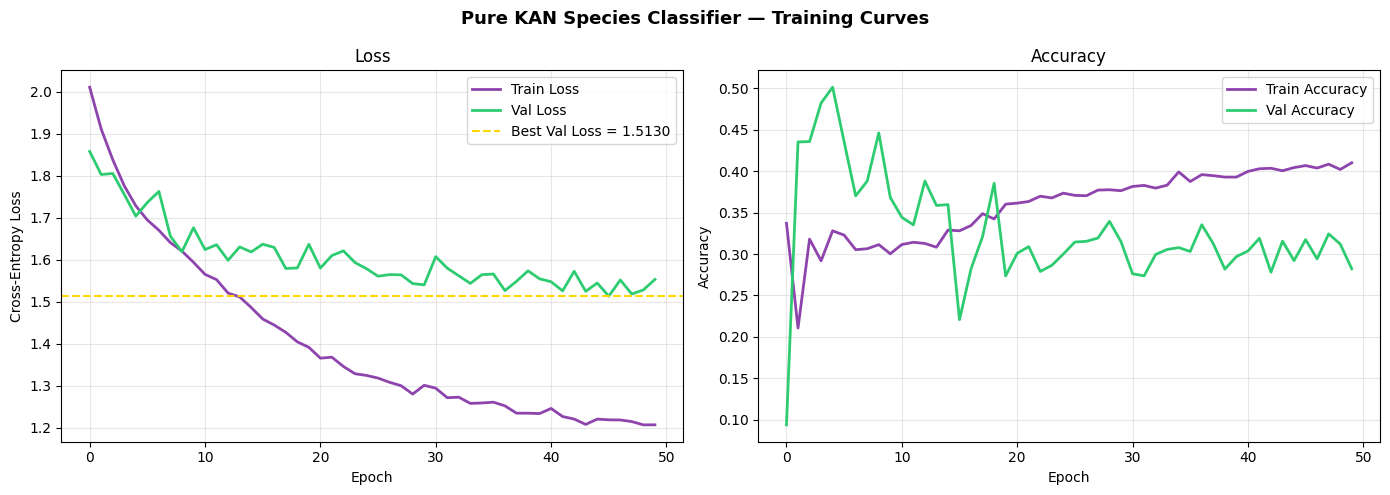

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(train_losses, color='#8e44ad', label='Train Loss', linewidth=2)
axes[0].plot(val_losses,   color='#2ecc71', label='Val Loss',   linewidth=2)
axes[0].axhline(best_val_loss, color='gold', linestyle='--', label=f'Best Val Loss = {best_val_loss:.4f}')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].set_title('Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(train_accs, color='#8e44ad', label='Train Accuracy', linewidth=2)
axes[1].plot(val_accs,   color='#2ecc71', label='Val Accuracy',   linewidth=2)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

fig.suptitle('Pure KAN Species Classifier — Training Curves', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('species_kan_classifier_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 🧪 STEP 10: Test-Set Evaluation — Confusion Matrix & Per-Species Report


TEST SET — Classification Report (Pure KAN)
              precision    recall  f1-score   support

     Class 0      0.109     0.450     0.175       347
    Elephant      0.933     0.307     0.462     10282
     Class 2      0.015     0.433     0.029        30
     Class 4      0.065     0.667     0.119        39
     Class 5      0.065     0.565     0.117       108
     Class 6      0.118     0.433     0.185       698
     Class 7      0.000     0.000     0.000         8
     Class 9      0.026     0.596     0.050        89

    accuracy                          0.325     11601
   macro avg      0.166     0.431     0.142     11601
weighted avg      0.838     0.325     0.428     11601



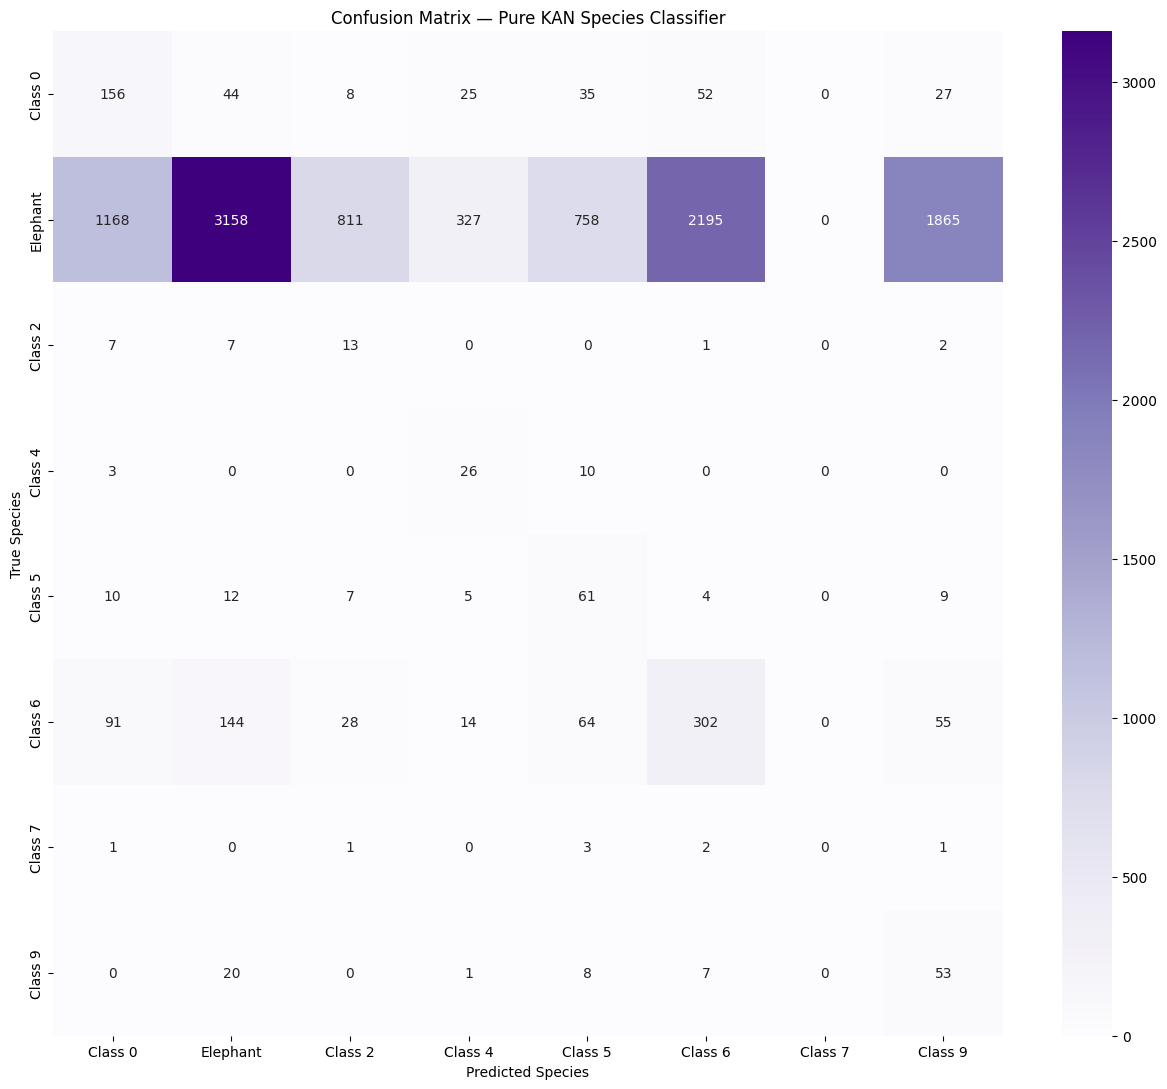

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

all_preds, all_true = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(yb.numpy())

target_names = [idx_to_name[i] for i in range(num_classes)]
print('=' * 70)
print('TEST SET — Classification Report (Pure KAN)')
print('=' * 70)
print(classification_report(all_true, all_preds, labels=list(range(num_classes)),
                             target_names=target_names, digits=3, zero_division=0))

cm = confusion_matrix(all_true, all_preds, labels=list(range(num_classes)))
plt.figure(figsize=(1.2*num_classes + 3, 1.0*num_classes + 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted Species'); plt.ylabel('True Species')
plt.title('Confusion Matrix — Pure KAN Species Classifier')
plt.tight_layout()
plt.savefig('species_kan_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()